# COVID-19 Case Analysis and Regression Modelling

## MSc Research Notebook

This notebook explores COVID-19 surveillance data and develops regression models to examine the relationship between reported COVID-19 indicators and **total confirmed cases**.

### Analysis workflow
1. Import the analysis libraries.
2. Load the source Excel dataset.
3. Normalize numeric variables and inspect missing values.
4. Explore distributions and relationships among indicators.
5. Assess multicollinearity using correlation analysis and Variance Inflation Factor (VIF).
6. Prepare training and testing datasets.
7. Compare Linear Regression, Ridge, Lasso, and Elastic Net models using error metrics and \(R^2\).

> **Important research note:** This notebook documents an exploratory modelling workflow. Missing values are replaced with zero in selected columns, and normalization is performed before the train/test split. These choices can affect the results and should be justified in the dissertation. In addition, the target (`ConfirmedTotal`) and some predictors may be mathematically or temporally related, so results should not automatically be interpreted as causal or as a future forecasting model.

### Input data
The notebook expects `COVID_19(JAN21_FEB23).xlsx` in the notebook's working directory. Column names are used as they appear in the source file, including `ComfirmedLastWeek` (spelling retained for compatibility).


In [1]:
# Loading Relevant Libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline 
import seaborn as sns

from math import sqrt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Dataset loading step: the next cell reads the COVID-19 Excel workbook.

# Loading Collected Dataset

In [3]:
# Load the source observations into a pandas DataFrame.

# Loading Collected Dataset
df=pd.read_excel('COVID_19(JAN21_FEB23).xlsx')

In [4]:
# Import MinMaxScaler to rescale numeric features to the [0, 1] interval.

from sklearn.preprocessing import MinMaxScaler

In [5]:
# Keep date and state identifiers out of the numeric scaling operation.

# Drop non-numeric and irrelevant columns for normalization
columns_to_exclude = [ 'DateReported', 'State']
numeric_df = df.drop(columns=columns_to_exclude)


In [6]:
# Fit the scaler to numeric columns and transform their values.

# Apply MinMax normalization
scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(numeric_df)

In [7]:
# Rebuild a DataFrame so scaled values retain their original feature names.

# Create a normalized DataFrame with the same column names
normalized_df = pd.DataFrame(normalized_data, columns=numeric_df.columns)

In [8]:
# Reattach identifiers so each normalized row can still be traced to its date/state.

# Reattach the non-numeric identifying columns
final_normalized_df = pd.concat([df[['DateReported', 'State']], normalized_df], axis=1)

In [9]:
# Preview the normalized dataset to verify its structure.

# Show the first few rows of the normalized DataFrame
final_normalized_df.head()

,DateReported,State,ConfirmedTotal,ComfirmedLastWeek,RecoveriesTotal,RecoveriesLastWeek,DeathTotal,DeathLastWeek,ActiveCases,TestingTotal,TestingLastWeek
0,2021-01-09,Abia,0.020516,0.001752,0.020525,0.004779,0.040312,0.0,0.000164,0.030349,0.031105
1,2021-01-09,Adamawa,0.011049,0.000000,0.010738,0.000000,0.039012,0.0,0.000199,0.021905,0.003681
2,2021-01-09,Akwa Ibom,0.043746,0.001869,0.042619,0.000000,0.054616,0.0,0.000633,0.035836,0.015911
3,2021-01-09,Anambra,0.025849,0.024293,0.023888,0.001500,0.022107,0.0,0.000838,0.037773,0.023929
4,2021-01-09,Bauchi,0.018271,0.003971,0.017877,0.000000,0.028609,0.0,0.000297,0.027066,0.002090


In [10]:
# Summarize the distribution of each normalized numeric variable.

# descrptive statistics for the dataset 
final_normalized_df.describe()

,ConfirmedTotal,ComfirmedLastWeek,RecoveriesTotal,RecoveriesLastWeek,DeathTotal,DeathLastWeek,ActiveCases,TestingTotal,TestingLastWeek
count,2960.000000,2955.000000,2959.000000,2958.000000,2960.000000,2957.000000,2886.000000,2960.000000,2865.000000
mean,0.055714,0.006369,0.053842,0.003083,0.091924,0.008575,0.002260,0.070465,0.045329
std,0.132610,0.032000,0.129380,0.023421,0.148820,0.042527,0.024411,0.130278,0.091289
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.010829,0.000000,0.009551,0.000000,0.026008,0.000000,0.000137,0.017349,0.002558
50%,0.020770,0.000234,0.019623,0.000000,0.041612,0.000000,0.000211,0.030250,0.013010
75%,0.044945,0.002920,0.044717,0.000945,0.094928,0.000000,0.000508,0.068536,0.045706
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
# Count missing values by column before applying the chosen treatment.

# Finding Missing Data
final_normalized_df.isnull().sum()

DateReported           0
State                  0
ConfirmedTotal         0
ComfirmedLastWeek      5
RecoveriesTotal        1
RecoveriesLastWeek     2
DeathTotal             0
DeathLastWeek          3
ActiveCases           74
TestingTotal           0
TestingLastWeek       95
dtype: int64

In [12]:
# Replace placeholder '?' values with NaN, then impute selected fields with zero.

# Filling missing data with the value (0)
final_normalized_df['RecoveriesTotal']=final_normalized_df['RecoveriesTotal'].replace('?',np.nan) #replace ? with nan
final_normalized_df['RecoveriesTotal']=final_normalized_df['RecoveriesTotal'].fillna(0)

final_normalized_df['RecoveriesLastWeek']=final_normalized_df['RecoveriesLastWeek'].replace('?',np.nan) #replace ? with nan
final_normalized_df['RecoveriesLastWeek']=final_normalized_df['RecoveriesLastWeek'].fillna(0)

final_normalized_df['DeathLastWeek']=final_normalized_df['DeathLastWeek'].replace('?',np.nan) #replace ? with nan
final_normalized_df['DeathLastWeek']=final_normalized_df['DeathLastWeek'].fillna(0)

final_normalized_df['ActiveCases']=final_normalized_df['ActiveCases'].replace('?',np.nan) #replace ? with nan
final_normalized_df['ActiveCases']=final_normalized_df['ActiveCases'].fillna(0)

final_normalized_df['TestingLastWeek']=final_normalized_df['TestingLastWeek'].replace('?',np.nan) #replace ? with nan
final_normalized_df['TestingLastWeek']=final_normalized_df['TestingLastWeek'].fillna(0)

final_normalized_df['ComfirmedLastWeek']=final_normalized_df['ComfirmedLastWeek'].replace('?',np.nan) #replace ? with nan
final_normalized_df['ComfirmedLastWeek']=final_normalized_df['ComfirmedLastWeek'].fillna(0)

In [13]:
# Verify the remaining missing-value counts after imputation.

# viewing the features for missing data 
final_normalized_df.isnull().sum()

DateReported          0
State                 0
ConfirmedTotal        0
ComfirmedLastWeek     0
RecoveriesTotal       0
RecoveriesLastWeek    0
DeathTotal            0
DeathLastWeek         0
ActiveCases           0
TestingTotal          0
TestingLastWeek       0
dtype: int64

In [14]:
# Inspect the resulting dataset after missing-value handling.

# viewing dataset after filling the missing value with 0
final_normalized_df

,DateReported,State,ConfirmedTotal,ComfirmedLastWeek,RecoveriesTotal,RecoveriesLastWeek,DeathTotal,DeathLastWeek,ActiveCases,TestingTotal,TestingLastWeek
0,2021-01-09,Abia,0.020516,0.001752,0.020525,0.004779,0.040312,0.0,0.000164,0.030349,0.031105
1,2021-01-09,Adamawa,0.011049,0.000000,0.010738,0.000000,0.039012,0.0,0.000199,0.021905,0.003681
2,2021-01-09,Akwa Ibom,0.043746,0.001869,0.042619,0.000000,0.054616,0.0,0.000633,0.035836,0.015911
3,2021-01-09,Anambra,0.025849,0.024293,0.023888,0.001500,0.022107,0.0,0.000838,0.037773,0.023929
4,2021-01-09,Bauchi,0.018271,0.003971,0.017877,0.000000,0.028609,0.0,0.000297,0.027066,0.002090
...,...,...,...,...,...,...,...,...,...,...,...
2955,2023-02-26,Rivers,0.173449,0.000000,0.175721,0.000000,0.198960,0.0,0.000155,0.370796,0.002621
2956,2023-02-26,Sokoto,0.007836,0.000000,0.007757,0.000000,0.033810,0.0,0.000119,0.071382,0.001560
2957,2023-02-26,Taraba,0.014464,0.000234,0.014160,0.000000,0.041612,0.0,0.000214,0.028484,0.006520
2958,2023-02-26,Yobe,0.006071,0.000000,0.006100,0.000000,0.009103,0.0,0.000131,0.028047,0.000000


In [15]:
# Remove identifier columns for analyses that require numeric predictors only.

# Dropping irrelevant features to the analysis
final_normalized_df=final_normalized_df.drop(['DateReported', 'State'],axis=1)
final_normalized_df

,ConfirmedTotal,ComfirmedLastWeek,RecoveriesTotal,RecoveriesLastWeek,DeathTotal,DeathLastWeek,ActiveCases,TestingTotal,TestingLastWeek
0,0.020516,0.001752,0.020525,0.004779,0.040312,0.0,0.000164,0.030349,0.031105
1,0.011049,0.000000,0.010738,0.000000,0.039012,0.0,0.000199,0.021905,0.003681
2,0.043746,0.001869,0.042619,0.000000,0.054616,0.0,0.000633,0.035836,0.015911
3,0.025849,0.024293,0.023888,0.001500,0.022107,0.0,0.000838,0.037773,0.023929
4,0.018271,0.003971,0.017877,0.000000,0.028609,0.0,0.000297,0.027066,0.002090
...,...,...,...,...,...,...,...,...,...
2955,0.173449,0.000000,0.175721,0.000000,0.198960,0.0,0.000155,0.370796,0.002621
2956,0.007836,0.000000,0.007757,0.000000,0.033810,0.0,0.000119,0.071382,0.001560
2957,0.014464,0.000234,0.014160,0.000000,0.041612,0.0,0.000214,0.028484,0.006520
2958,0.006071,0.000000,0.006100,0.000000,0.009103,0.0,0.000131,0.028047,0.000000


C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


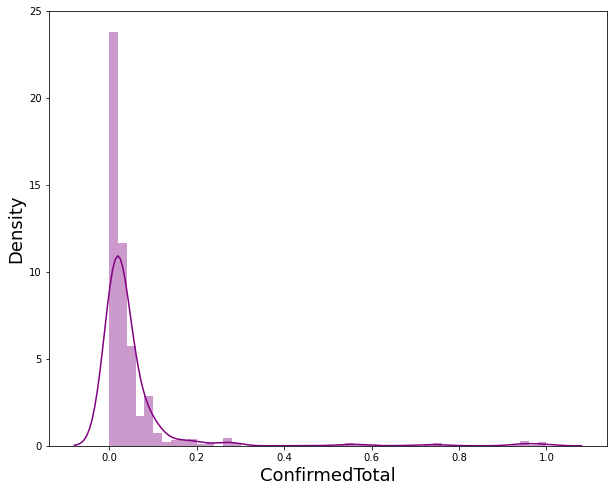

In [16]:
# Plot the distribution of cumulative confirmed cases.

#Visualizing total confirmed cases
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('', rotation=90, fontsize=18)
sns.distplot(final_normalized_df['ConfirmedTotal'], color='purple')
plt.savefig("ctc.jpg")

C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


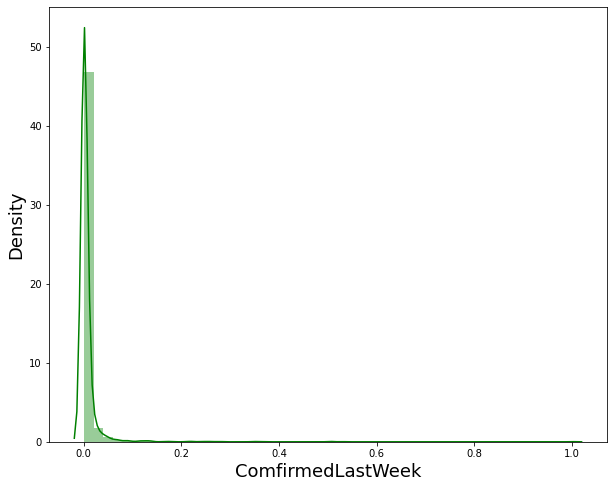

In [17]:
# Plot the distribution of confirmed cases reported in the previous week.

#Visualizing weekly comfirmed cases
plt.figure(figsize = (10, 8))
plt.xlabel('',fontsize=18)
plt.ylabel('', rotation=90, fontsize=18)
sns.distplot(final_normalized_df['ComfirmedLastWeek'], color='green')
plt.savefig("clwc.jpg")

C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


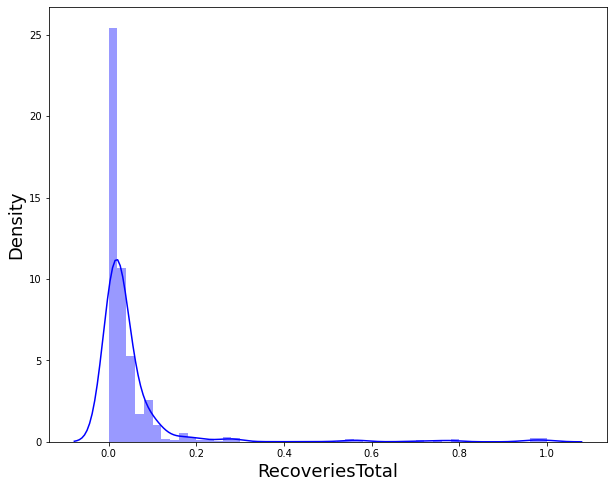

In [18]:
# Plot the distribution of cumulative recoveries.

#Visualizing total recovered cases
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.distplot(final_normalized_df['RecoveriesTotal'], color='blue')
plt.savefig("rtc.jpg")

C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


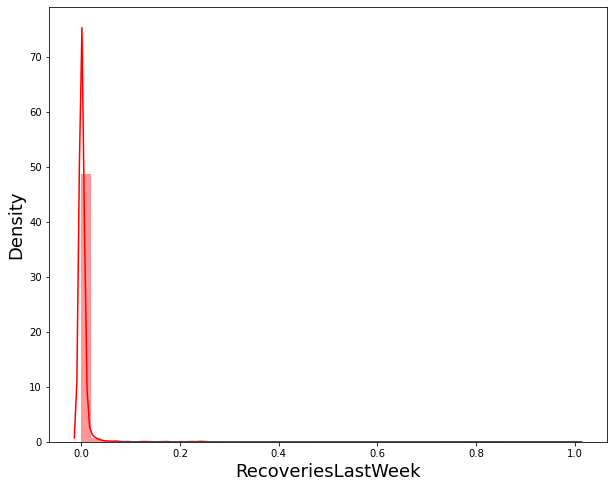

In [19]:
# Plot the distribution of recoveries reported in the previous week.

#Visualizing weekly recovered cases
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('', rotation=90, fontsize=18)
sns.distplot(final_normalized_df['RecoveriesLastWeek'], color='red')
plt.savefig("rlwc.jpg")

C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


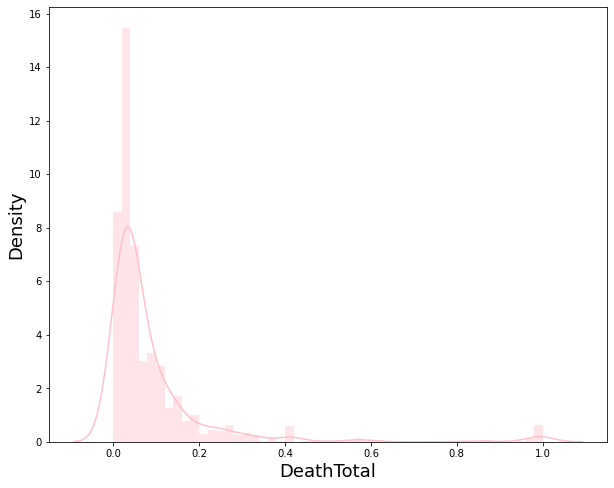

In [20]:
# Plot the distribution of cumulative deaths.

#Visualizing total death cases
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.distplot(final_normalized_df['DeathTotal'], color='pink')
plt.savefig("dtc.jpg")

C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


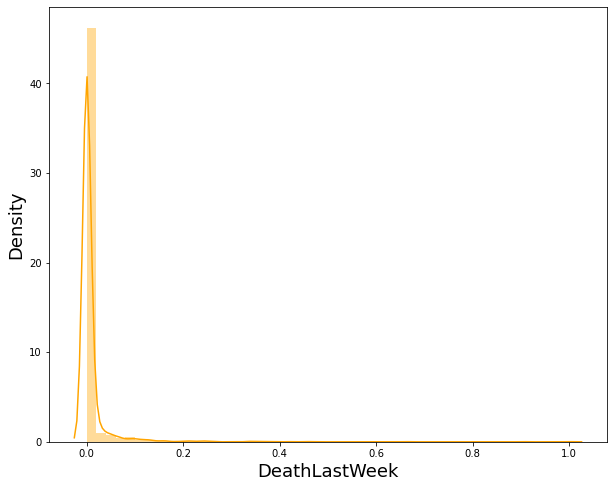

In [21]:
# Plot the distribution of deaths reported in the previous week.

#Visualizing weekly death cases
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.distplot(final_normalized_df['DeathLastWeek'], color='orange')
plt.savefig("dlwc.jpg")

C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


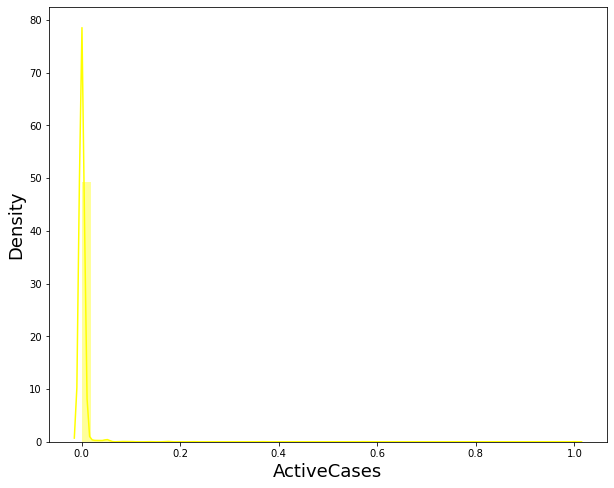

In [22]:
# Plot the distribution of active cases.

#Visualizing total active cases
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.distplot(final_normalized_df['ActiveCases'], color='yellow')
plt.savefig("ac.jpg")

C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


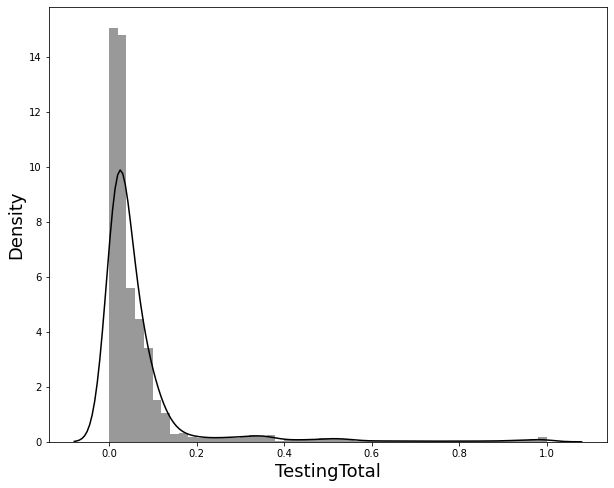

In [23]:
# Plot the distribution of cumulative tests conducted.

#Visualizing total tested cases
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.distplot(final_normalized_df['TestingTotal'], color='black')
plt.savefig("ttc.jpg")

C:\Users\Dynastes\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


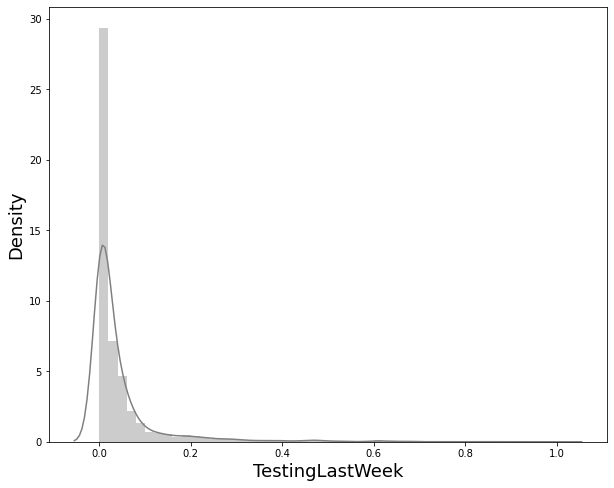

In [24]:
# Plot the distribution of tests conducted in the previous week.

#Visualizing weekly tested cases
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.distplot(final_normalized_df['TestingLastWeek'], color='gray')
plt.savefig("tlwc.jpg")

In [25]:
# Define the response variable: cumulative confirmed cases.

#Setting up Dependent Variable
df_target=final_normalized_df['ConfirmedTotal']
df_target.head(n=7)

0    0.020516
1    0.011049
2    0.043746
3    0.025849
4    0.018271
5    0.012469
6    0.020266
Name: ConfirmedTotal, dtype: float64

In [26]:
# Define candidate predictors by excluding the response variable.

# Setting up Independent Variables
df_feature=final_normalized_df.drop('ConfirmedTotal',axis=1)
df_feature

,ComfirmedLastWeek,RecoveriesTotal,RecoveriesLastWeek,DeathTotal,DeathLastWeek,ActiveCases,TestingTotal,TestingLastWeek
0,0.001752,0.020525,0.004779,0.040312,0.0,0.000164,0.030349,0.031105
1,0.000000,0.010738,0.000000,0.039012,0.0,0.000199,0.021905,0.003681
2,0.001869,0.042619,0.000000,0.054616,0.0,0.000633,0.035836,0.015911
3,0.024293,0.023888,0.001500,0.022107,0.0,0.000838,0.037773,0.023929
4,0.003971,0.017877,0.000000,0.028609,0.0,0.000297,0.027066,0.002090
...,...,...,...,...,...,...,...,...
2955,0.000000,0.175721,0.000000,0.198960,0.0,0.000155,0.370796,0.002621
2956,0.000000,0.007757,0.000000,0.033810,0.0,0.000119,0.071382,0.001560
2957,0.000234,0.014160,0.000000,0.041612,0.0,0.000214,0.028484,0.006520
2958,0.000000,0.006100,0.000000,0.009103,0.0,0.000131,0.028047,0.000000


## Exploratory relationship analysis

The following cells inspect pairwise correlations and scatterplots among the predictor variables. These plots help identify potentially redundant predictors and relationships that may influence regression estimates.

In [27]:
# Display the predictor correlation matrix for an initial collinearity check.

### Colinearity

In [28]:
# Calculate pairwise correlations among the candidate predictors.

df_feature.corr()

,ComfirmedLastWeek,RecoveriesTotal,RecoveriesLastWeek,DeathTotal,DeathLastWeek,ActiveCases,TestingTotal,TestingLastWeek
ComfirmedLastWeek,1.000000,0.378341,0.332257,0.371092,0.342553,0.243735,0.310684,0.565855
RecoveriesTotal,0.378341,1.000000,0.264534,0.934213,0.192236,0.098741,0.941981,0.668652
RecoveriesLastWeek,0.332257,0.264534,1.000000,0.242995,0.318526,0.182291,0.202022,0.335444
DeathTotal,0.371092,0.934213,0.242995,1.000000,0.239091,0.092138,0.892433,0.662918
DeathLastWeek,0.342553,0.192236,0.318526,0.239091,1.000000,0.218499,0.120349,0.302107
ActiveCases,0.243735,0.098741,0.182291,0.092138,0.218499,1.000000,0.025146,0.094189
TestingTotal,0.310684,0.941981,0.202022,0.892433,0.120349,0.025146,1.000000,0.638131
TestingLastWeek,0.565855,0.668652,0.335444,0.662918,0.302107,0.094189,0.638131,1.000000


In [29]:
# Visualize predictor correlations in a heatmap.

corelation = df_feature.corr()

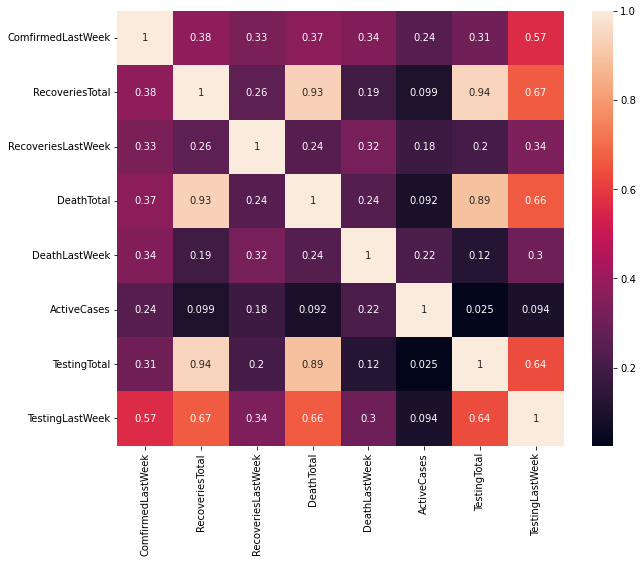

In [30]:
# Cluster correlated predictors to reveal groups of related features.

plt.figure(figsize = (10,8 ))
sns.heatmap(corelation, xticklabels=corelation.columns, yticklabels=corelation.columns, annot=True)
plt.savefig("heatmap.jpg")

<Figure size 288x288 with 0 Axes>

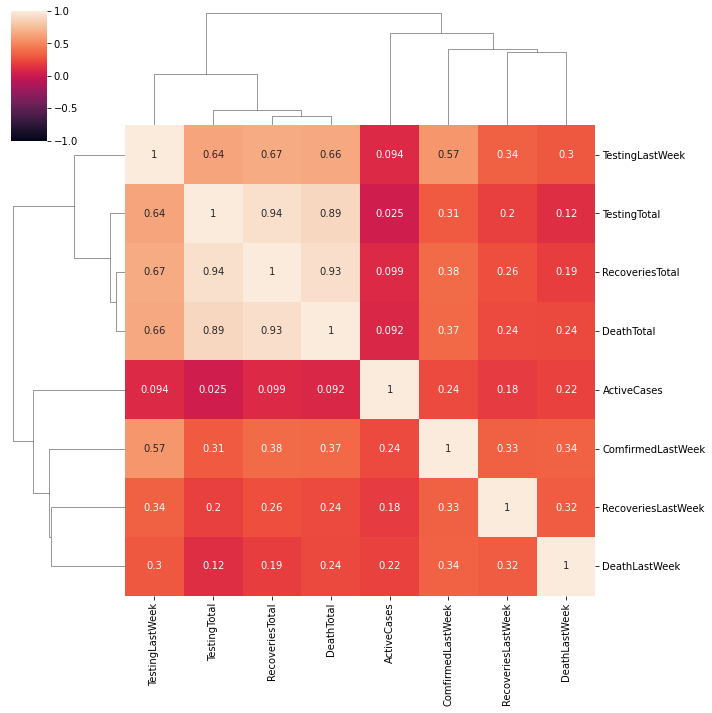

In [31]:
plt.figure(figsize = (4, 4))
clustermap = sns.clustermap(df_feature.corr(), vmin = -1, vmax = 1, annot = True)
plt.savefig("clustermap.jpg")

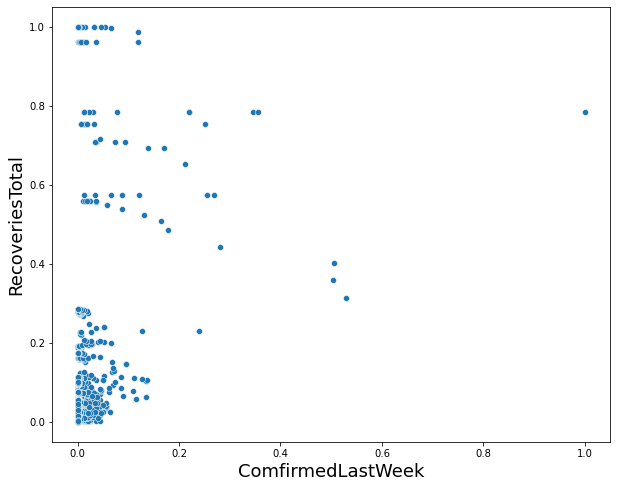

In [32]:
# Visualizing the relationship between Last Week Comfirmed and Total recoveries   
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='ComfirmedLastWeek', y='RecoveriesTotal', data=df_feature)
plt.savefig("clwcVSrtc.jpg")

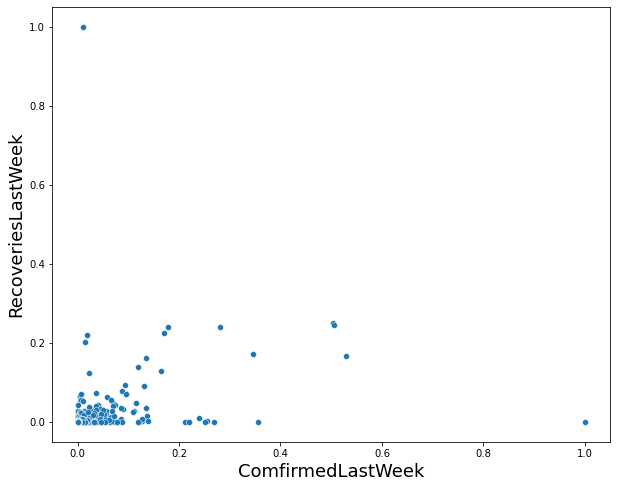

In [33]:
# Visualizing the relationship between Last Week Comfirmed and Total recoveries   
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='ComfirmedLastWeek', y='RecoveriesLastWeek', data=df_feature)
plt.savefig("clwcVSrlwc.jpg")

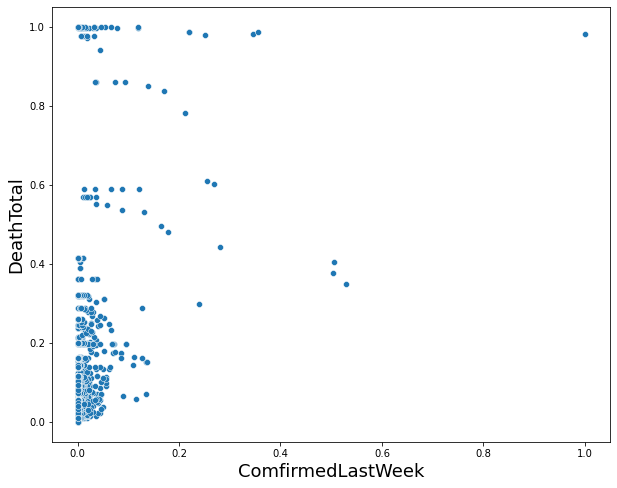

In [34]:
# Visualizing the relationship between Last week recoveries and last week testing 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='ComfirmedLastWeek', y='DeathTotal', data=df_feature)
plt.savefig("clwcVSdtc.jpg")

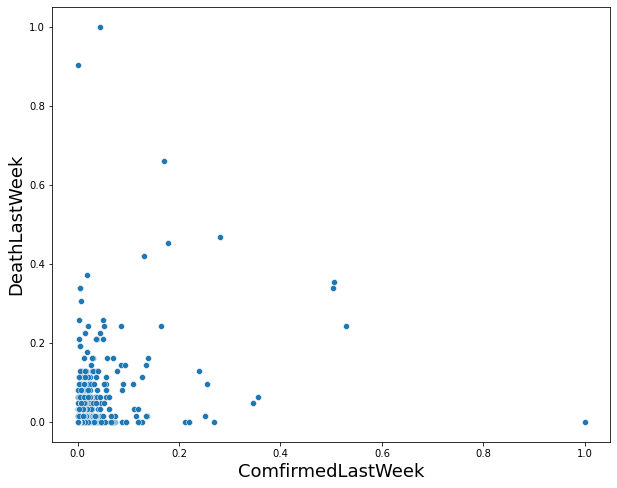

In [35]:
# Visualizing the relationship between Last week recoveries and last week testing 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='ComfirmedLastWeek', y='DeathLastWeek', data=df_feature)
plt.savefig("clwcVSdlwc.jpg")

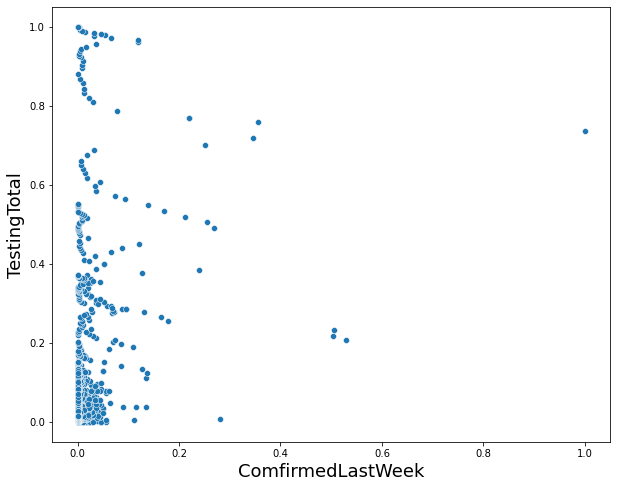

In [36]:
# Visualizing the relationship between Last week recoveries and last week testing 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='ComfirmedLastWeek', y='TestingTotal', data=df_feature)
plt.savefig("clwcVSttc.jpg")

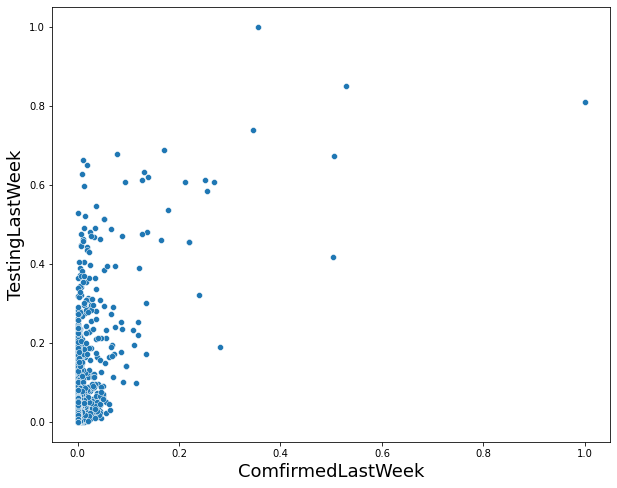

In [37]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='ComfirmedLastWeek', y='TestingLastWeek', data=df_feature)
plt.savefig("clwcVStlwc.jpg")

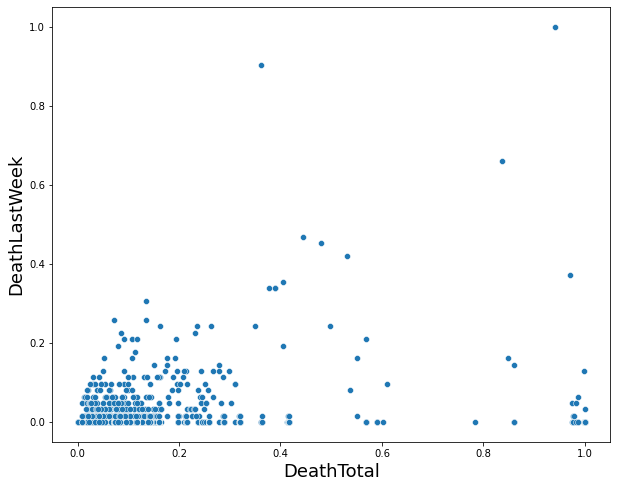

In [38]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathTotal', y='DeathLastWeek', data=df_feature)
plt.savefig("dtcVSdlwc.jpg")

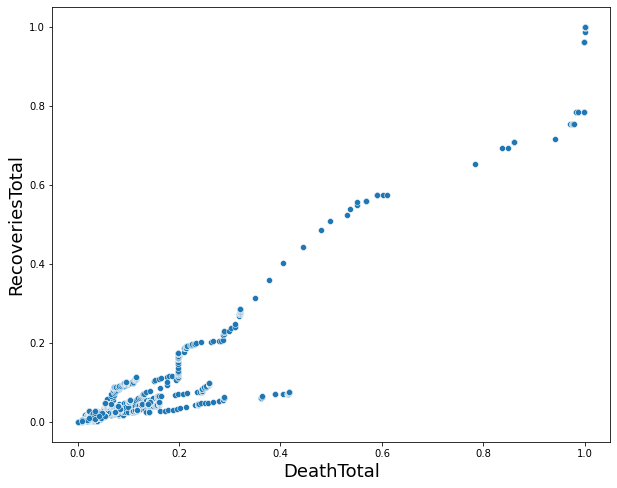

In [39]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathTotal', y='RecoveriesTotal', data=df_feature)
plt.savefig("dtcVSrtc.jpg")

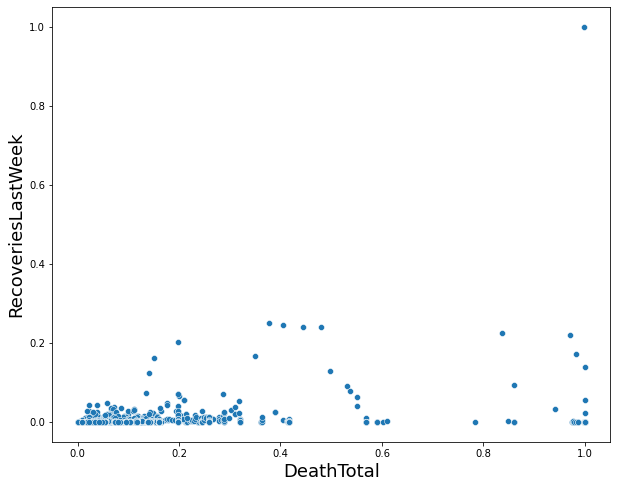

In [40]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathTotal', y='RecoveriesLastWeek', data=df_feature)
plt.savefig("dtcVSrlwc.jpg")

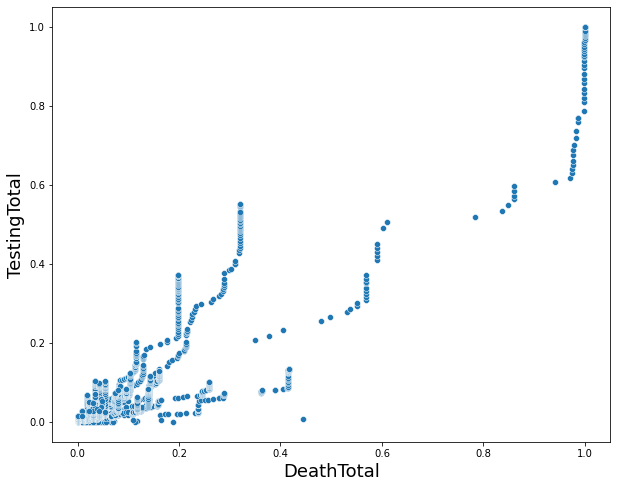

In [41]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathTotal', y='TestingTotal', data=df_feature)
plt.savefig("dtcVSttc.jpg")

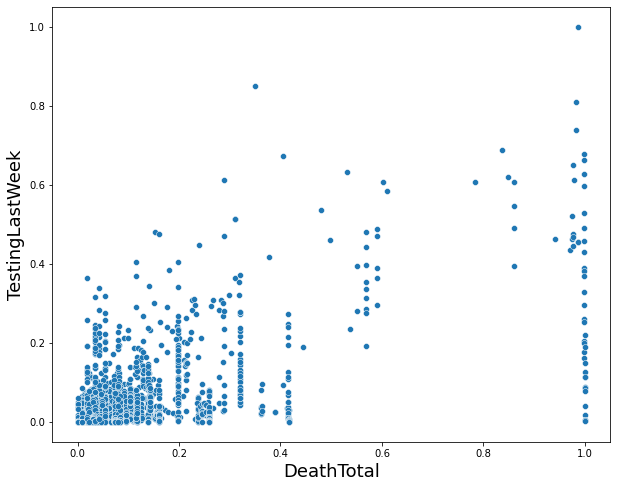

In [42]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathTotal', y='TestingLastWeek', data=df_feature)
plt.savefig("dtcVStlwc.jpg")

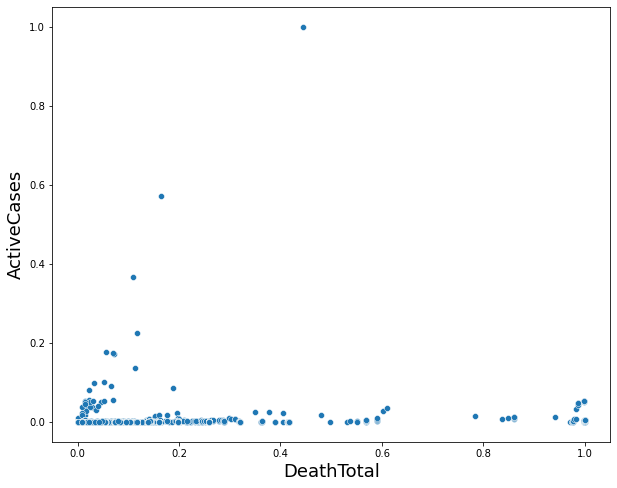

In [43]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathTotal', y='ActiveCases', data=df_feature)
plt.savefig("dtcVSac.jpg")

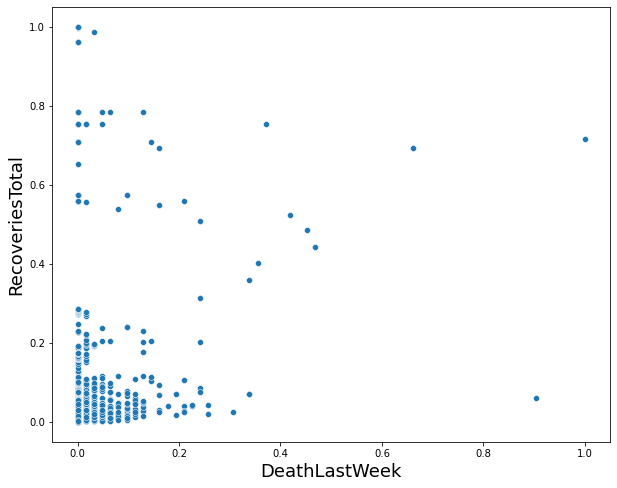

In [44]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathLastWeek', y='RecoveriesTotal', data=df_feature)
plt.savefig("dlwcVSrtc.jpg")

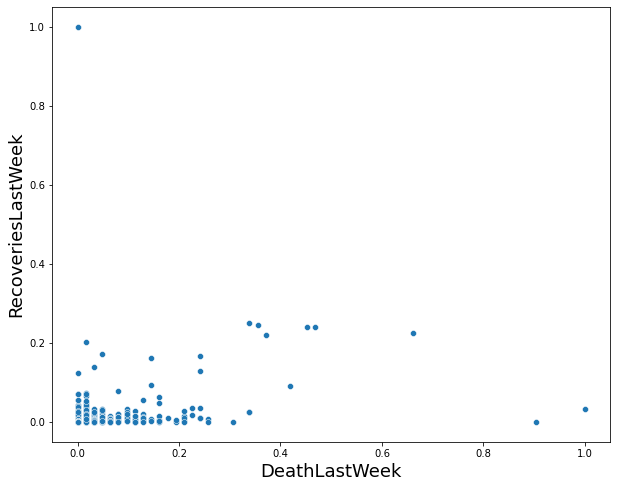

In [45]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathLastWeek', y='RecoveriesLastWeek', data=df_feature)
plt.savefig("dlwcVSrlwc.jpg")

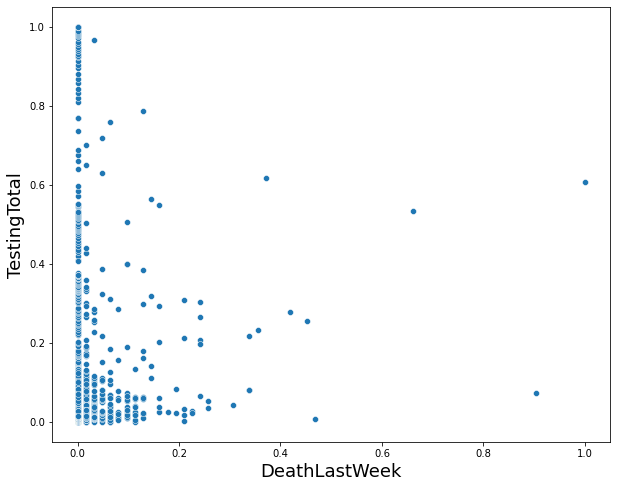

In [46]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathLastWeek', y='TestingTotal', data=df_feature)
plt.savefig("dlwcVSttc.jpg")

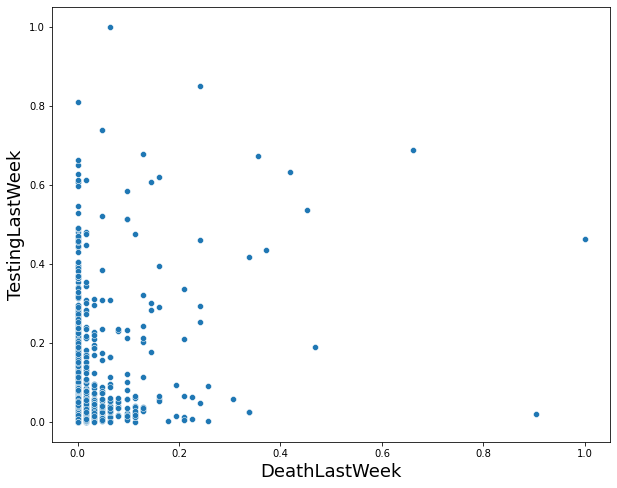

In [47]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathLastWeek', y='TestingLastWeek', data=df_feature)
plt.savefig("dlwcVStlwc.jpg")

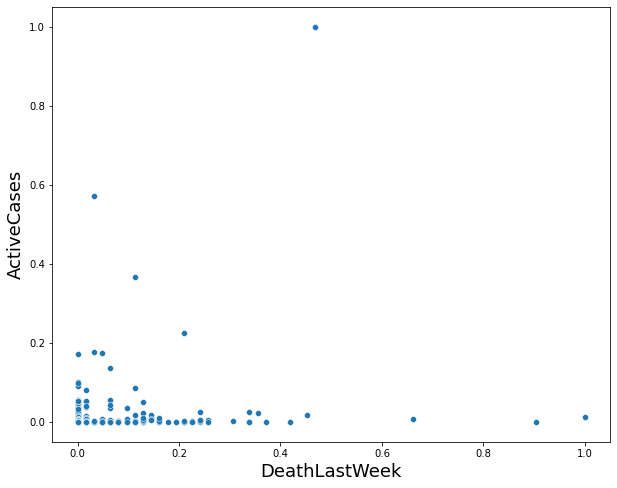

In [48]:
# Visualizing the relationship between Last week confirmed cases and last week death
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='DeathLastWeek', y='ActiveCases', data=df_feature)
plt.savefig("dlwcVSac.jpg")

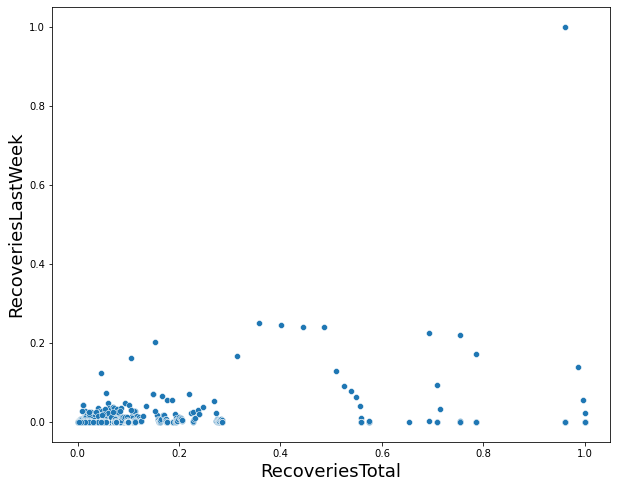

In [49]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='RecoveriesTotal', y='RecoveriesLastWeek', data=df_feature)
plt.savefig("rtcVSrlwc.jpg")

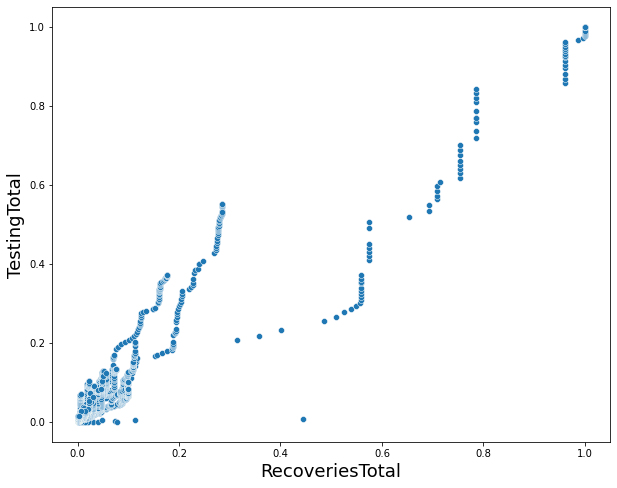

In [50]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='RecoveriesTotal', y='TestingTotal', data=df_feature)
plt.savefig("rtcVSttc.jpg")

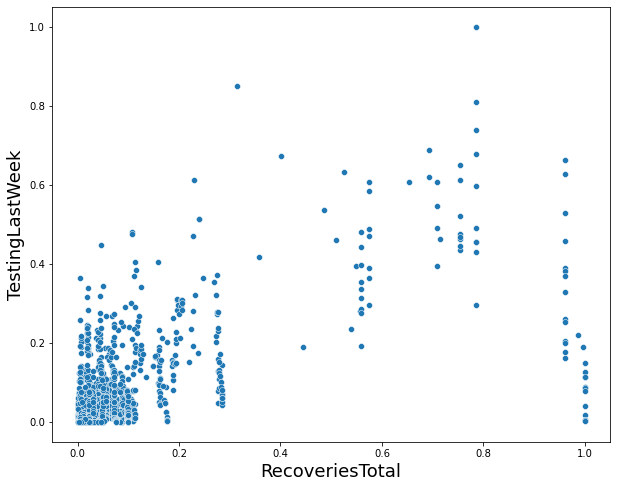

In [51]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='RecoveriesTotal', y='TestingLastWeek', data=df_feature)
plt.savefig("rtcVStlwc.jpg")

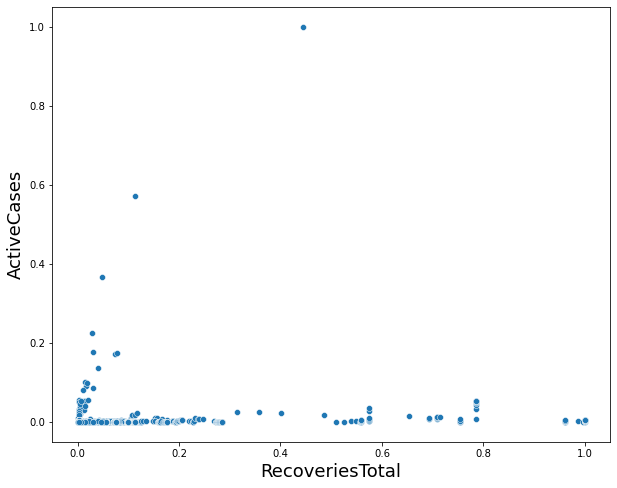

In [52]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='RecoveriesTotal', y='ActiveCases', data=df_feature)
plt.savefig("rtcVSac.jpg")

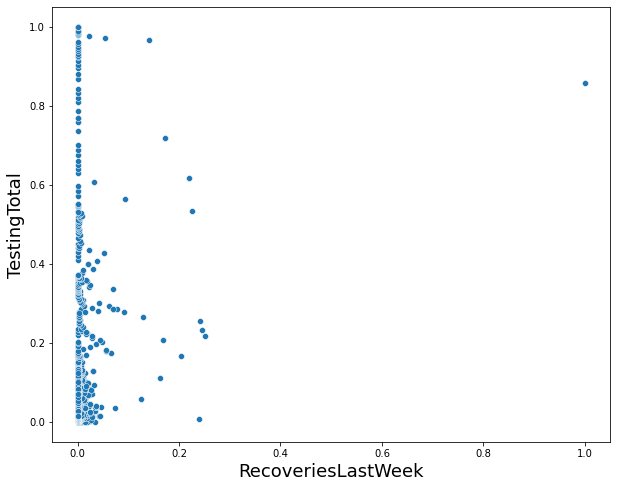

In [53]:



# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='RecoveriesLastWeek', y='TestingTotal', data=df_feature)
plt.savefig("rlwcVSttc.jpg")

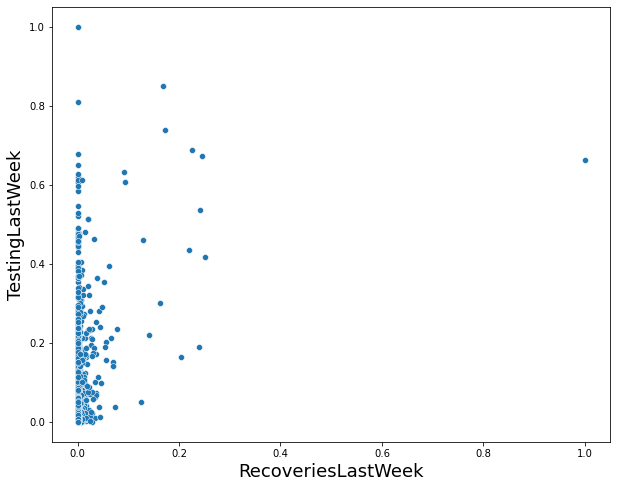

In [54]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='RecoveriesLastWeek', y='TestingLastWeek', data=df_feature)
plt.savefig("rlwcVStlwc.jpg")

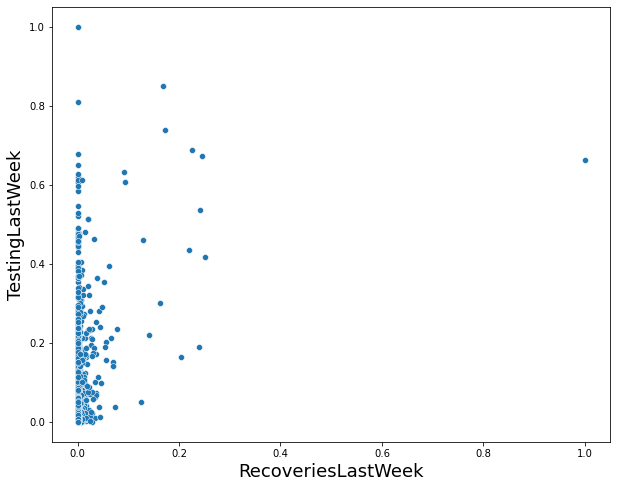

In [55]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='RecoveriesLastWeek', y='TestingLastWeek', data=df_feature)
plt.savefig("rlwcVStlwc.jpg")

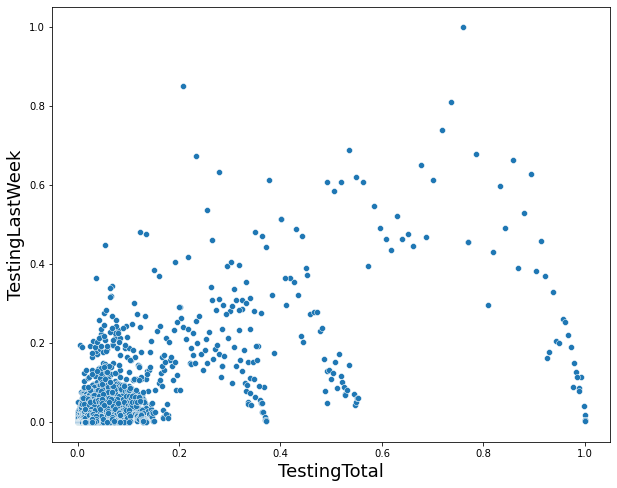

In [56]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='TestingTotal', y='TestingLastWeek', data=df_feature)
plt.savefig("ttcVStlwc.jpg")

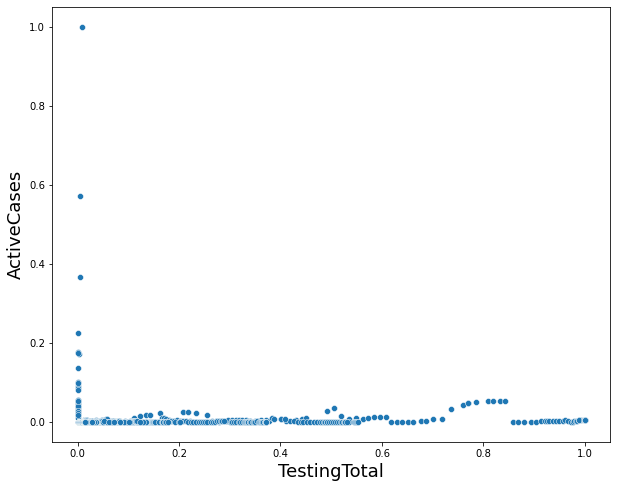

In [57]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='TestingTotal', y='ActiveCases', data=df_feature)
plt.savefig("ttcVSac.jpg")

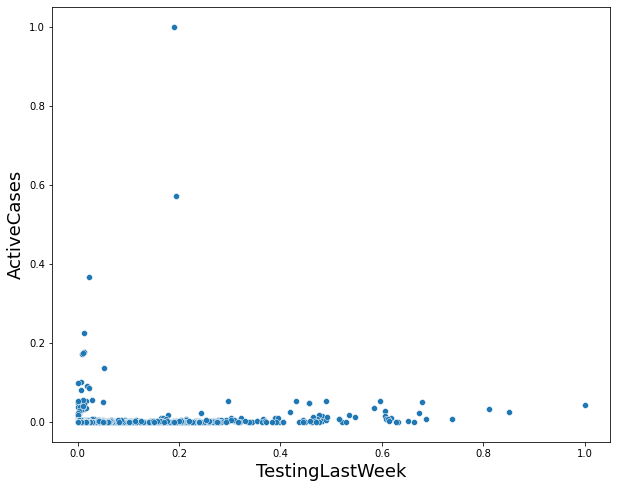

In [58]:
# Visualizing the relationship between active cases and total cases tested 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='TestingLastWeek', y='ActiveCases', data=df_feature)
plt.savefig("tlwcVSac.jpg")

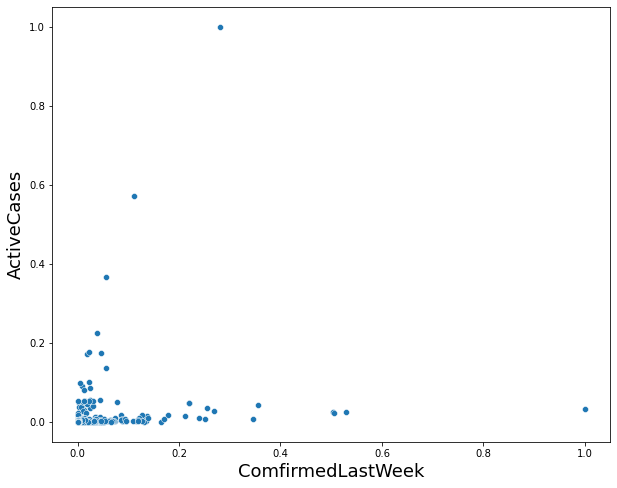

In [59]:
# Visualizing the relationship between Last week recoveries and last week testing 
plt.figure(figsize = (10, 8))
plt.xlabel('', fontsize=18)
plt.ylabel('',rotation=90, fontsize=18)
sns.scatterplot(x='ComfirmedLastWeek', y='ActiveCases', data=df_feature)
plt.savefig("clwcVSac.jpg")

## Variance Inflation Factor (VIF)

VIF quantifies how strongly each predictor can be explained by the other predictors. High values can indicate multicollinearity. The notebook first calculates VIF using the full predictor set, then repeats the calculation after removing selected variables.

In [60]:
# Calculate VIF values for each predictor in the current feature matrix.

# the independent variables set
X = df_feature
  
# VIF dataframe
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
  
# calculating VIF for each feature
vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
print(vif_data)

              Feature        VIF
0   ComfirmedLastWeek   1.711327
1     RecoveriesTotal  14.220086
2  RecoveriesLastWeek   1.270297
3          DeathTotal   9.601746
4       DeathLastWeek   1.343647
5         ActiveCases   1.127986
6        TestingTotal  11.685354
7     TestingLastWeek   2.956326


In [61]:
# Create a reduced predictor set by excluding selected highly related variables.

df_feature_m=final_normalized_df.drop(['ConfirmedTotal', 'RecoveriesTotal','TestingTotal'],axis=1)

In [62]:
# Recalculate VIF for the reduced predictor set.

# the independent variables set
X = df_feature_m
  
# VIF dataframe
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
  
# calculating VIF for each feature
vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
print(vif_data)

              Feature       VIF
0   ComfirmedLastWeek  1.682940
1  RecoveriesLastWeek  1.250538
2          DeathTotal  2.210771
3       DeathLastWeek  1.281557
4         ActiveCases  1.111716
5     TestingLastWeek  2.846718


In [63]:
# Split the reduced-feature data into training and test subsets.

X_train,X_test,y_train,y_test=train_test_split(df_feature_m,df_target,test_size=0.2,random_state=42)

In [64]:
# Confirm the dimensions of the training and test partitions.

print('X_train', X_train.shape)
print('X_test', X_test.shape)
print('y_train', y_train.shape)
print('y_test', y_test.shape)

X_train (2368, 6)
X_test (592, 6)
y_train (2368,)
y_test (592,)


## Model comparison and overfitting assessment

The following cells fit Linear Regression, Elastic Net, Lasso, and Ridge models. Training-set and test-set errors are compared as a basic check of generalization. A larger test error than training error can indicate weaker performance on unseen observations.

In [65]:
# Compare in-sample and test-set mean squared error for four regression models.

# Initialize models
alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and MSE
    y_train_pred = model.predict(X_train)
    mse_in_sample = mean_squared_error(y_train, y_train_pred)

    # Out-of-sample predictions and MSE
    y_test_pred = model.predict(X_test)
    mse_out_of_sample = mean_squared_error(y_test, y_test_pred)

    # Differences between in-sample and out-of-sample MSE
    mse_difference = mse_out_of_sample - mse_in_sample

    # Store results
    results[model_name] = {
        "In-sample MSE": mse_in_sample,
        "Out-of-sample MSE": mse_out_of_sample,
        "Difference": mse_difference
    }

# Print results
for model_name, metrics in results.items():
    print(f"{model_name}:")
    print(f"  In-sample MSE: {metrics['In-sample MSE']:.4f}")
    print(f"  Out-of-sample MSE: {metrics['Out-of-sample MSE']:.4f}")
    print(f"  Difference (Out-of-sample - In-sample): {metrics['Difference']:.4f}\n")


Linear Regression:
  In-sample MSE: 0.0019
  Out-of-sample MSE: 0.0021
  Difference (Out-of-sample - In-sample): 0.0001

ElasticNet:
  In-sample MSE: 0.0175
  Out-of-sample MSE: 0.0177
  Difference (Out-of-sample - In-sample): 0.0002

Lasso:
  In-sample MSE: 0.0175
  Out-of-sample MSE: 0.0177
  Difference (Out-of-sample - In-sample): 0.0002

Ridge:
  In-sample MSE: 0.0019
  Out-of-sample MSE: 0.0021
  Difference (Out-of-sample - In-sample): 0.0001



In [66]:
# Compare in-sample and test-set root mean squared error for four regression models.

# Initialize models
alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and RMSE
    y_train_pred = model.predict(X_train)
    rmse_in_sample = np.sqrt(mean_squared_error(y_train, y_train_pred))

    # Out-of-sample predictions and RMSE
    y_test_pred = model.predict(X_test)
    rmse_out_of_sample = np.sqrt(mean_squared_error(y_test, y_test_pred))

    # Differences between in-sample and out-of-sample RMSE
    rmse_difference = rmse_out_of_sample - rmse_in_sample

    # Store results
    results[model_name] = {
        "In-sample RMSE": rmse_in_sample,
        "Out-of-sample RMSE": rmse_out_of_sample,
        "Difference": rmse_difference
    }

# Print results
for model_name, metrics in results.items():
    print(f"{model_name}:")
    print(f"  In-sample RMSE: {metrics['In-sample RMSE']:.4f}")
    print(f"  Out-of-sample RMSE: {metrics['Out-of-sample RMSE']:.4f}")
    print(f"  Difference (In-sample - Out-of-sample): {metrics['Difference']:.4f}\n")


Linear Regression:
  In-sample RMSE: 0.0440
  Out-of-sample RMSE: 0.0456
  Difference (In-sample - Out-of-sample): 0.0016

ElasticNet:
  In-sample RMSE: 0.1325
  Out-of-sample RMSE: 0.1331
  Difference (In-sample - Out-of-sample): 0.0007

Lasso:
  In-sample RMSE: 0.1325
  Out-of-sample RMSE: 0.1331
  Difference (In-sample - Out-of-sample): 0.0007

Ridge:
  In-sample RMSE: 0.0441
  Out-of-sample RMSE: 0.0457
  Difference (In-sample - Out-of-sample): 0.0016



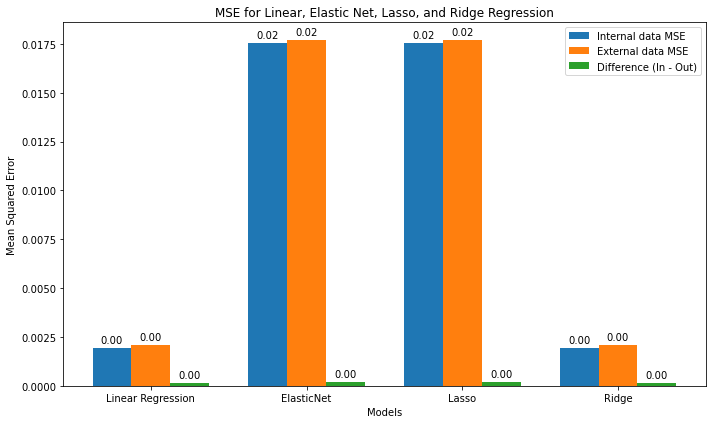

<Figure size 432x288 with 0 Axes>

In [67]:
# Visualize MSE values and their train/test differences for each model.

alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and MSE
    y_train_pred = model.predict(X_train)
    mse_in_sample = mean_squared_error(y_train, y_train_pred)

    # Out-of-sample predictions and MSE
    y_test_pred = model.predict(X_test)
    mse_out_of_sample = mean_squared_error(y_test, y_test_pred)

    # Differences between in-sample and out-of-sample MSE
    mse_difference = mse_out_of_sample - mse_in_sample

    # Store results
    results[model_name] = {
        "In-sample MSE": mse_in_sample,
        "Out-of-sample MSE": mse_out_of_sample,
        "Difference": mse_difference
    }

# Prepare data for plotting
model_names = list(results.keys())
in_sample_mse = [results[model]["In-sample MSE"] for model in model_names]
out_of_sample_mse = [results[model]["Out-of-sample MSE"] for model in model_names]
mse_differences = [results[model]["Difference"] for model in model_names]

# Create bar chart
x = np.arange(len(model_names))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width, in_sample_mse, width, label='Internal data MSE')
bars2 = ax.bar(x, out_of_sample_mse, width, label='External data MSE')
bars3 = ax.bar(x + width, mse_differences, width, label='Difference (In - Out)')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Models')
ax.set_ylabel('Mean Squared Error')
ax.set_title('MSE for Linear, Elastic Net, Lasso, and Ridge Regression')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

# Add value labels on top of the bars
def add_value_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

add_value_labels(bars1)
add_value_labels(bars2)
add_value_labels(bars3)

# Show plot
plt.tight_layout()
plt.show()
plt.savefig("cavif.jpg")


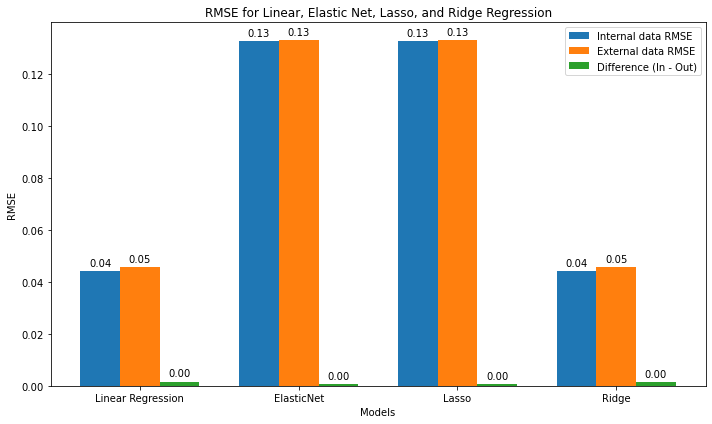

<Figure size 432x288 with 0 Axes>

In [68]:
# Visualize RMSE values and their train/test differences for each model.

# Initialize models
alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and RMSE
    y_train_pred = model.predict(X_train)
    rmse_in_sample = np.sqrt(mean_squared_error(y_train, y_train_pred))

    # Out-of-sample predictions and RMSE
    y_test_pred = model.predict(X_test)
    rmse_out_of_sample = np.sqrt(mean_squared_error(y_test, y_test_pred))

    # Differences between in-sample and out-of-sample RMSE
    rmse_difference = rmse_out_of_sample - rmse_in_sample

    # Store results
    results[model_name] = {
        "In-sample RMSE": rmse_in_sample,
        "Out-of-sample RMSE": rmse_out_of_sample,
        "Difference": rmse_difference
    }

# Prepare data for plotting
model_names = list(results.keys())
in_sample_rmse = [results[model]["In-sample RMSE"] for model in model_names]
out_of_sample_rmse = [results[model]["Out-of-sample RMSE"] for model in model_names]
rmse_differences = [results[model]["Difference"] for model in model_names]

# Create bar chart
x = np.arange(len(model_names))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width, in_sample_rmse, width, label='Internal data RMSE')
bars2 = ax.bar(x, out_of_sample_rmse, width, label='External data RMSE')
bars3 = ax.bar(x + width, rmse_differences, width, label='Difference (In - Out)')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Models')
ax.set_ylabel('RMSE')
ax.set_title('RMSE for Linear, Elastic Net, Lasso, and Ridge Regression')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

# Add value labels on top of the bars
def add_value_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

add_value_labels(bars1)
add_value_labels(bars2)
add_value_labels(bars3)

# Show plot
plt.tight_layout()
plt.show()
plt.savefig("RMSEavif.jpg")

In [69]:
# Fit each regression model and report its test-set coefficient of determination (R²).

# Initialize models
linear_model = LinearRegression()
lasso_model = Lasso(alpha=0.1)
ridge_model = Ridge(alpha=0.1)
elastic_net_model = ElasticNet(alpha=0.1, l1_ratio=0.5)

# Fit models
linear_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)
elastic_net_model.fit(X_train, y_train)

# Make predictions
linear_pred = linear_model.predict(X_test)
lasso_pred = lasso_model.predict(X_test)
ridge_pred = ridge_model.predict(X_test)
elastic_net_pred = elastic_net_model.predict(X_test)

# Calculate R-squared values
linear_r2 = r2_score(y_test, linear_pred)
lasso_r2 = r2_score(y_test, lasso_pred)
ridge_r2 = r2_score(y_test, ridge_pred)
elastic_net_r2 = r2_score(y_test, elastic_net_pred)

# Display R-squared values
print(f"Linear Regression R²: {linear_r2:.4f}")
print(f"Lasso Regression R²: {lasso_r2:.4f}")
print(f"Ridge Regression R²: {ridge_r2:.4f}")
print(f"Elastic Net R²: {elastic_net_r2:.4f}")


Linear Regression R²: 0.8826
Lasso Regression R²: -0.0000
Ridge Regression R²: 0.8826
Elastic Net R²: -0.0000


## Model comparison using the full feature set

This section repeats the train/test evaluation using all available predictors. Compare these results with the reduced-feature analysis above; keep the split and evaluation setup in mind when interpreting differences.

In [70]:
# Create a train/test split using the full set of candidate predictors.

X_train,X_test,y_train,y_test=train_test_split(df_feature,df_target,test_size=0.3,random_state=6738)

In [71]:
# Confirm the dimensions of the full-feature training and test partitions.

print('X_train', X_train.shape)
print('X_test', X_test.shape)
print('y_train', y_train.shape)
print('y_test', y_test.shape)

X_train (2072, 8)
X_test (888, 8)
y_train (2072,)
y_test (888,)


In [72]:
# Evaluate the full-feature models using training and test MSE.

# Initialize models
alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and MSE
    y_train_pred = model.predict(X_train)
    mse_in_sample = mean_squared_error(y_train, y_train_pred)

    # Out-of-sample predictions and MSE
    y_test_pred = model.predict(X_test)
    mse_out_of_sample = mean_squared_error(y_test, y_test_pred)

    # Differences between in-sample and out-of-sample MSE
    mse_difference = mse_out_of_sample - mse_in_sample

    # Store results
    results[model_name] = {
        "In-sample MSE": mse_in_sample,
        "Out-of-sample MSE": mse_out_of_sample,
        "Difference": mse_difference
    }

# Print results
for model_name, metrics in results.items():
    print(f"{model_name}:")
    print(f"  In-sample MSE: {metrics['In-sample MSE']:.4f}")
    print(f"  Out-of-sample MSE: {metrics['Out-of-sample MSE']:.4f}")
    print(f"  Difference (Out-of-sample - In-sample): {metrics['Difference']:.4f}\n")


Linear Regression:
  In-sample MSE: 0.0001
  Out-of-sample MSE: 0.0001
  Difference (Out-of-sample - In-sample): 0.0000

ElasticNet:
  In-sample MSE: 0.0169
  Out-of-sample MSE: 0.0191
  Difference (Out-of-sample - In-sample): 0.0022

Lasso:
  In-sample MSE: 0.0169
  Out-of-sample MSE: 0.0191
  Difference (Out-of-sample - In-sample): 0.0022

Ridge:
  In-sample MSE: 0.0001
  Out-of-sample MSE: 0.0002
  Difference (Out-of-sample - In-sample): 0.0000



In [73]:
# Evaluate the full-feature models using training and test RMSE.

# Initialize models
alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and RMSE
    y_train_pred = model.predict(X_train)
    rmse_in_sample = np.sqrt(mean_squared_error(y_train, y_train_pred))

    # Out-of-sample predictions and RMSE
    y_test_pred = model.predict(X_test)
    rmse_out_of_sample = np.sqrt(mean_squared_error(y_test, y_test_pred))

    # Differences between in-sample and out-of-sample RMSE
    rmse_difference = rmse_out_of_sample - rmse_in_sample

    # Store results
    results[model_name] = {
        "In-sample RMSE": rmse_in_sample,
        "Out-of-sample RMSE": rmse_out_of_sample,
        "Difference": rmse_difference
    }

# Print results
for model_name, metrics in results.items():
    print(f"{model_name}:")
    print(f"  In-sample RMSE: {metrics['In-sample RMSE']:.4f}")
    print(f"  Out-of-sample RMSE: {metrics['Out-of-sample RMSE']:.4f}")
    print(f"  Difference (In-sample - Out-of-sample): {metrics['Difference']:.4f}\n")


Linear Regression:
  In-sample RMSE: 0.0072
  Out-of-sample RMSE: 0.0093
  Difference (In-sample - Out-of-sample): 0.0020

ElasticNet:
  In-sample RMSE: 0.1301
  Out-of-sample RMSE: 0.1382
  Difference (In-sample - Out-of-sample): 0.0080

Lasso:
  In-sample RMSE: 0.1301
  Out-of-sample RMSE: 0.1382
  Difference (In-sample - Out-of-sample): 0.0080

Ridge:
  In-sample RMSE: 0.0114
  Out-of-sample RMSE: 0.0133
  Difference (In-sample - Out-of-sample): 0.0019



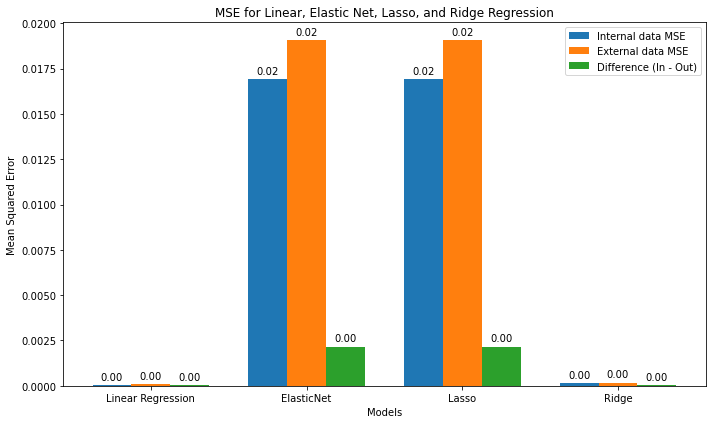

<Figure size 432x288 with 0 Axes>

In [74]:
# Plot full-feature model MSE comparisons.

alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and MSE
    y_train_pred = model.predict(X_train)
    mse_in_sample = mean_squared_error(y_train, y_train_pred)

    # Out-of-sample predictions and MSE
    y_test_pred = model.predict(X_test)
    mse_out_of_sample = mean_squared_error(y_test, y_test_pred)

    # Differences between in-sample and out-of-sample MSE
    mse_difference = mse_out_of_sample - mse_in_sample

    # Store results
    results[model_name] = {
        "In-sample MSE": mse_in_sample,
        "Out-of-sample MSE": mse_out_of_sample,
        "Difference": mse_difference
    }

# Prepare data for plotting
model_names = list(results.keys())
in_sample_mse = [results[model]["In-sample MSE"] for model in model_names]
out_of_sample_mse = [results[model]["Out-of-sample MSE"] for model in model_names]
mse_differences = [results[model]["Difference"] for model in model_names]

# Create bar chart
x = np.arange(len(model_names))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width, in_sample_mse, width, label='Internal data MSE')
bars2 = ax.bar(x, out_of_sample_mse, width, label='External data MSE')
bars3 = ax.bar(x + width, mse_differences, width, label='Difference (In - Out)')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Models')
ax.set_ylabel('Mean Squared Error')
ax.set_title('MSE for Linear, Elastic Net, Lasso, and Ridge Regression')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

# Add value labels on top of the bars
def add_value_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

add_value_labels(bars1)
add_value_labels(bars2)
add_value_labels(bars3)

# Show plot
plt.tight_layout()
plt.show()
plt.savefig("MSEb_4vif.jpg")

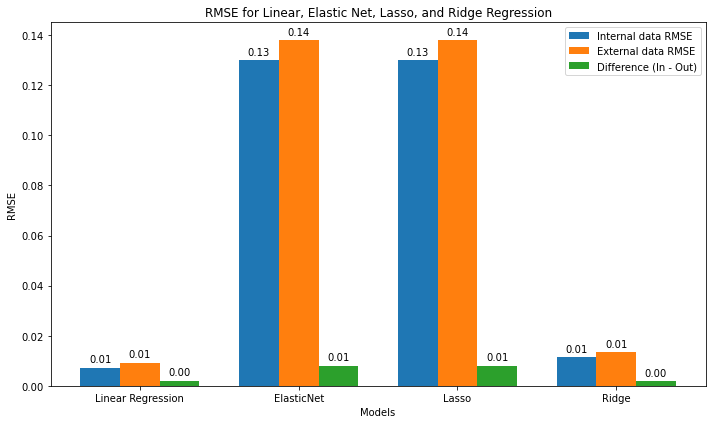

<Figure size 432x288 with 0 Axes>

In [75]:
# Plot full-feature model RMSE comparisons.

# Initialize models
alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and RMSE
    y_train_pred = model.predict(X_train)
    rmse_in_sample = np.sqrt(mean_squared_error(y_train, y_train_pred))

    # Out-of-sample predictions and RMSE
    y_test_pred = model.predict(X_test)
    rmse_out_of_sample = np.sqrt(mean_squared_error(y_test, y_test_pred))

    # Differences between in-sample and out-of-sample RMSE
    rmse_difference = rmse_out_of_sample - rmse_in_sample

    # Store results
    results[model_name] = {
        "In-sample RMSE": rmse_in_sample,
        "Out-of-sample RMSE": rmse_out_of_sample,
        "Difference": rmse_difference
    }

# Prepare data for plotting
model_names = list(results.keys())
in_sample_rmse = [results[model]["In-sample RMSE"] for model in model_names]
out_of_sample_rmse = [results[model]["Out-of-sample RMSE"] for model in model_names]
rmse_differences = [results[model]["Difference"] for model in model_names]

# Create bar chart
x = np.arange(len(model_names))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width, in_sample_rmse, width, label='Internal data RMSE')
bars2 = ax.bar(x, out_of_sample_rmse, width, label='External data RMSE')
bars3 = ax.bar(x + width, rmse_differences, width, label='Difference (In - Out)')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Models')
ax.set_ylabel('RMSE')
ax.set_title('RMSE for Linear, Elastic Net, Lasso, and Ridge Regression')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

# Add value labels on top of the bars
def add_value_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

add_value_labels(bars1)
add_value_labels(bars2)
add_value_labels(bars3)

# Show plot
plt.tight_layout()
plt.show()
plt.savefig("RMSEb_4vif.jpg")


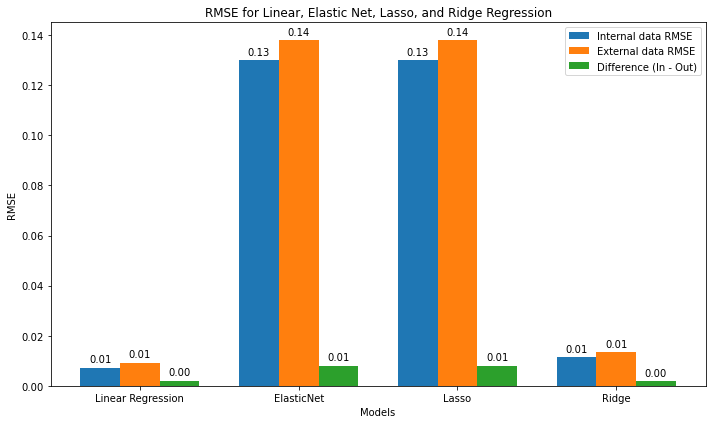

<Figure size 432x288 with 0 Axes>

In [77]:
# Plot full-feature model RMSE comparisons.

# Initialize models
alpha = 1.0  # Regularization strength
l1_ratio = 0.5  # Mix ratio for ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "ElasticNet": ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42),
    "Lasso": Lasso(alpha=alpha, random_state=42),
    "Ridge": Ridge(alpha=alpha, random_state=42)
}

# Store results
results = {}

for model_name, model in models.items():
    # Fit the model
    model.fit(X_train, y_train)
    
    # In-sample predictions and RMSE
    y_train_pred = model.predict(X_train)
    rmse_in_sample = np.sqrt(mean_squared_error(y_train, y_train_pred))

    # Out-of-sample predictions and RMSE
    y_test_pred = model.predict(X_test)
    rmse_out_of_sample = np.sqrt(mean_squared_error(y_test, y_test_pred))

    # Differences between in-sample and out-of-sample RMSE
    rmse_difference = rmse_out_of_sample - rmse_in_sample

    # Store results
    results[model_name] = {
        "In-sample RMSE": rmse_in_sample,
        "Out-of-sample RMSE": rmse_out_of_sample,
        "Difference": rmse_difference
    }

# Prepare data for plotting
model_names = list(results.keys())
in_sample_rmse = [results[model]["In-sample RMSE"] for model in model_names]
out_of_sample_rmse = [results[model]["Out-of-sample RMSE"] for model in model_names]
rmse_differences = [results[model]["Difference"] for model in model_names]

# Create bar chart
x = np.arange(len(model_names))  # the label locations
width = 0.25  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width, in_sample_rmse, width, label='Internal data RMSE')
bars2 = ax.bar(x, out_of_sample_rmse, width, label='External data RMSE')
bars3 = ax.bar(x + width, rmse_differences, width, label='Difference (In - Out)')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Models')
ax.set_ylabel('RMSE')
ax.set_title('RMSE for Linear, Elastic Net, Lasso, and Ridge Regression')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

# Add value labels on top of the bars
def add_value_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

add_value_labels(bars1)
add_value_labels(bars2)
add_value_labels(bars3)

# Show plot
plt.tight_layout()
plt.show()
plt.savefig("RMSEb_4vif.jpg")
